# Ranking mensual frente a clasificación

¿Mejora el ordenamiento al entrenar con pares positivo–negativo del mismo mes?
Comparamos las mismas features, capacidad, fechas y semillas. AUC/Gini es el objetivo
principal; precision, recall y lift del top 5%/10% son resultados secundarios.
No se usa test ni se modifica la entrega. Los scores de ranking **no son probabilidades**.

In [2]:
from pathlib import Path
import json
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown

assert sys.version_info[:2] == (3, 13)
HERE = Path.cwd()
if not (HERE / "PROTOCOLO.md").exists():
    HERE = HERE / "nuevas-tareas" / "ranking_mensual"
sys.path.insert(0, str(HERE))
from experimento import sha
OUT = HERE / "resultados"
if not (OUT / "manifiesto.json").exists():
    subprocess.run([sys.executable, str(HERE / "experimento.py")], check=True, cwd=HERE)
if not (OUT / "verificacion.json").exists():
    subprocess.run([sys.executable, str(HERE / "verificar.py")], check=True, cwd=HERE)
manifest = json.loads((OUT / "manifiesto.json").read_text(encoding="utf-8"))
assert manifest["script_sha256"] == sha(HERE / "experimento.py")
assert manifest["train_sha256"] == sha(HERE.parents[1] / "train.csv")
assert manifest["protocolo_sha256"] == sha(HERE / "PROTOCOLO.md")
assert manifest["features_sha256"] == sha(HERE.parent / "experimentos.py")
selection = json.loads((OUT / "seleccion_pre_noviembre.json").read_text(encoding="utf-8"))
m = pd.read_csv(OUT / "metricas_ensemble.csv")
s = pd.read_csv(OUT / "metricas_semillas.csv")
p = pd.read_csv(OUT / "predicciones_ensemble.csv")
for frame in [m, s, p]:
    frame[["features", "metodo"]] = frame.config.str.split("__", expand=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
display(pd.Series(json.loads((OUT / "auditorias.json").read_text()), name="Auditoría previa"))
display(pd.Series(json.loads((OUT / "verificacion.json").read_text()), name="Auditoría de resultados"))

filas                                               110100
usuarios                                             24628
features                   {'Entrada': 23, 'Historia': 33}
invariancia_futuro                                    True
independencia_etiquetas                               True
solo_one_hot                                          True
metricas_empates                                      True
Name: Auditoría previa, dtype: object

ajustes                                                                   64
metricas_ensemble                                                         32
predicciones_semillas                                                 637600
predicciones_ensemble                                                 318800
etiquetas_alineadas                                                     True
metricas_recalculadas                                                   True
bootstrap_verificado                                                    True
pares_auditados                                                         True
pesos_mensuales_iguales                                                 True
parametros_compartidos     [iterations, depth, learning_rate, l2_leaf_reg...
seleccion_sin_noviembre                                                 True
hashes                                                                  True
Name: Auditoría de resultados, dtype: object

## Comparación controlada

Cada grupo es un mes. Los pares contienen un conversor y un no conversor del mismo
mes; el no conversor puede convertir más adelante. No se agrupa por cliente ni por
duración, porque el objetivo es ordenar **todos los candidatos de un mes**.

Dos bloques: **Entrada**, foto inicial + duración (23), e **Historia**, información
conocida al mes evaluado (33). Cuatro pérdidas/ponderaciones: Logloss natural,
Logloss con peso igual por mes, PairLogit con 20k y con 100k pares por mes.
Los pares pequeños están incluidos en los grandes. Dos semillas, 64 ajustes.

Ensemble prefijado: promedio del rango percentil de dos semillas, por mes, sin etiquetas.
Esta transformación no implica probabilidades ni calibración. Mismas 250 iteraciones,
profundidad 4 y controles del protocolo para las cuatro variantes.

In [3]:
pairs = pd.read_csv(OUT / "pares.csv")
display(pairs.loc[pairs.mes_evaluado.eq(11)].groupby("pares").agg(
    cobertura_positivos_min=("cobertura_positivos", "min"),
    cobertura_negativos_min=("cobertura_negativos", "min"),
    peso_min_mes=("pares", "min"), peso_max_mes=("pares", "max")))
display(pd.read_csv(OUT / "ajustes.csv").groupby("config").agg(
    ajustes=("semilla", "size"), segundos_medios=("segundos", "mean"), segundos_total=("segundos", "sum")))

,cobertura_positivos_min,cobertura_negativos_min,peso_min_mes,peso_max_mes
pares,,,,
20000,1.0,0.891257,20000,20000
100000,1.0,0.999886,100000,100000


,ajustes,segundos_medios,segundos_total
config,,,
Entrada__Logloss_mensual,8,2.139724,17.117790
Entrada__Logloss_natural,8,2.930757,23.446059
Entrada__PairLogit_100k,8,14.008001,112.064009
Entrada__PairLogit_20k,8,7.145299,57.162392
Historia__Logloss_mensual,8,2.380482,19.043854
Historia__Logloss_natural,8,2.347308,18.778466
Historia__PairLogit_100k,8,14.098317,112.786539
Historia__PairLogit_20k,8,6.949997,55.599978


## AUC temporal y elección antes de noviembre

Entrenamiento expansivo hasta el mes anterior. Selección por AUC media agosto–octubre
con igual peso por mes. Noviembre ya fue explorado antes: no es un test independiente
virgen. Se informa el ensemble y la variación entre las dos semillas, sin llamarla IC.

mes,8,9,10,11,media_ago_oct
config,,,,,
Entrada__PairLogit_20k,0.6313,0.6278,0.6329,0.6162,0.6307
Entrada__Logloss_mensual,0.6302,0.6273,0.6328,0.6180,0.6301
Entrada__Logloss_natural,0.6299,0.6273,0.6328,0.6186,0.6300
Historia__Logloss_natural,0.6319,0.6245,0.6330,0.6175,0.6298
Historia__Logloss_mensual,0.6315,0.6242,0.6336,0.6173,0.6298
Historia__PairLogit_20k,0.6306,0.6238,0.6340,0.6142,0.6295
Entrada__PairLogit_100k,0.6279,0.6251,0.6295,0.6134,0.6275
Historia__PairLogit_100k,0.6282,0.6207,0.6296,0.6107,0.6262


Mejor ranking elegido: Entrada__PairLogit_20k
Mejor clasificación elegida: Entrada__Logloss_mensual
Control con las mismas features: Entrada__Logloss_mensual


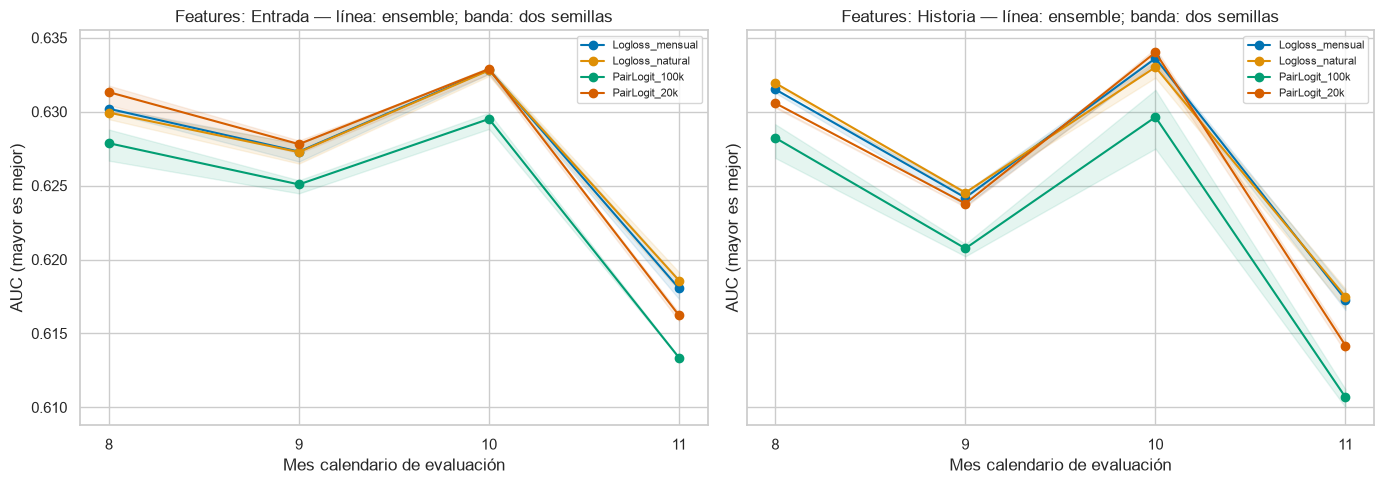

In [4]:
table = m.pivot(index="config", columns="mes", values="AUC")
table["media_ago_oct"] = table[[8, 9, 10]].mean(axis=1)
display(table.sort_values("media_ago_oct", ascending=False).style.format("{:.4f}"))
print("Mejor ranking elegido:", selection["ranking"])
print("Mejor clasificación elegida:", selection["clasificacion"])
print("Control con las mismas features:", selection["control_matched"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
palette = dict(zip(sorted(m.metodo.unique()), sns.color_palette("colorblind", 4)))
for ax, feat in zip(axes, ["Entrada", "Historia"]):
    for method in sorted(m.metodo.unique()):
        line = m.loc[m.features.eq(feat) & m.metodo.eq(method)].sort_values("mes")
        seed_rows = s.loc[s.features.eq(feat) & s.metodo.eq(method)]
        band = seed_rows.groupby("mes").AUC.agg(["min", "max"])
        ax.plot(line.mes, line.AUC, marker="o", label=method, color=palette[method])
        ax.fill_between(band.index, band["min"], band["max"], alpha=.10, color=palette[method])
    ax.set(xlabel="Mes calendario de evaluación", ylabel="AUC (mayor es mejor)",
           xticks=[8, 9, 10, 11], title=f"Features: {feat} — línea: ensemble; banda: dos semillas")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Priorizar campañas: top 5% y 10%

K=ceil(fracción de clientes). Recall es qué fracción de todos los conversores queda
dentro de los K elegidos. Precision es qué fracción de los elegidos convierte. Lift
divide esa precision entre la tasa mensual. Ante empates en el corte, se reporta la
captura esperada si el desempate fuera aleatorio. No se usa ID para desempatar.

,config,n,eventos,AUC,Gini,K5,precision5,recall5,lift5,K10,precision10,recall10,lift10
25,Entrada__Logloss_natural,9500,1439,0.618575,0.237150,475,0.315789,0.104239,2.084781,950,0.292632,0.193190,1.931897
24,Entrada__Logloss_mensual,9500,1439,0.618046,0.236091,475,0.313684,0.103544,2.070883,950,0.292632,0.193190,1.931897
29,Historia__Logloss_natural,9500,1439,0.617477,0.234955,475,0.327368,0.108061,2.161223,950,0.289474,0.191105,1.911049
28,Historia__Logloss_mensual,9500,1439,0.617292,0.234585,475,0.317895,0.104934,2.098680,950,0.291579,0.192495,1.924948
27,Entrada__PairLogit_20k,9500,1439,0.616214,0.232428,475,0.315789,0.104239,2.084781,950,0.287368,0.189715,1.897151
31,Historia__PairLogit_20k,9500,1439,0.614182,0.228365,475,0.317895,0.104934,2.098680,950,0.289474,0.191105,1.911049
26,Entrada__PairLogit_100k,9500,1439,0.613353,0.226707,475,0.317895,0.104934,2.098680,950,0.284211,0.187630,1.876303
30,Historia__PairLogit_100k,9500,1439,0.610682,0.221365,475,0.315789,0.104239,2.084781,950,0.285263,0.188325,1.883252


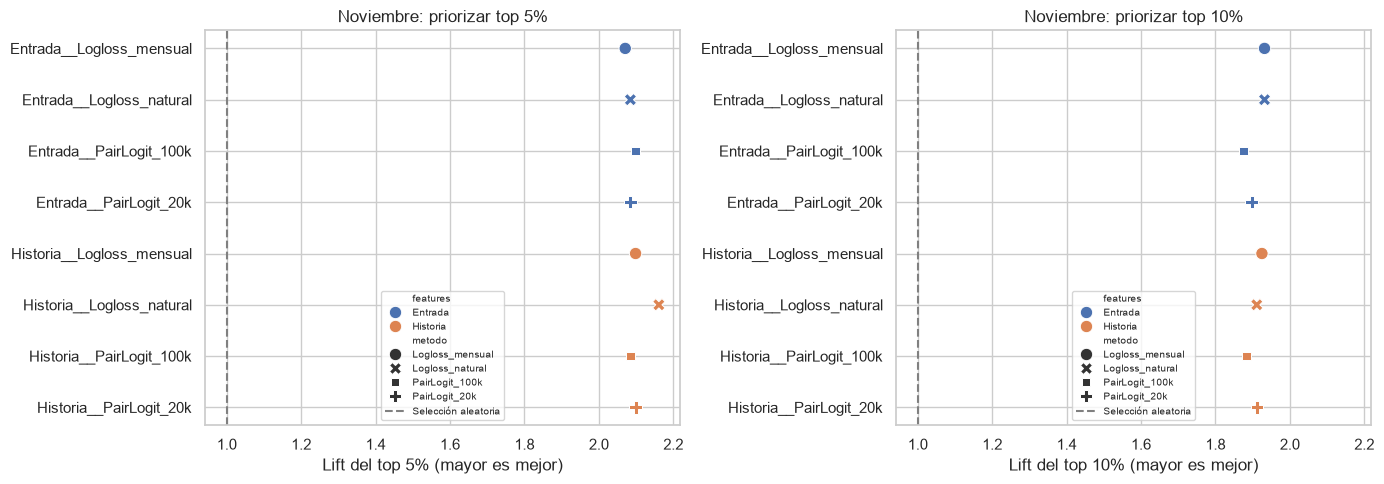

In [5]:
nov = m.loc[m.mes.eq(11)]
display(nov[["config", "n", "eventos", "AUC", "Gini", "K5", "precision5", "recall5", "lift5",
             "K10", "precision10", "recall10", "lift10"]].sort_values("AUC", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, pct in zip(axes, [5, 10]):
    sns.scatterplot(data=nov, x=f"lift{pct}", y="config", hue="features", style="metodo", s=80, ax=ax)
    ax.axvline(1, color="gray", linestyle="--", label="Selección aleatoria")
    ax.set(xlabel=f"Lift del top {pct}% (mayor es mejor)", ylabel="", title=f"Noviembre: priorizar top {pct}%")
    ax.legend(fontsize=7, loc="best")
plt.tight_layout()
plt.show()

## Diferencias pareadas e incertidumbre

Candidato de ranking y clasificador seleccionados antes de noviembre. Bootstrap de
2.000 remuestreos de clientes: compara scores sobre los mismos clientes en cada réplica.
Es condicional a los ajustes; no recoge toda la incertidumbre de entrenar ni la selección
previa. Top-K es análisis secundario, no criterio para escoger un ganador retrospectivo.

,candidato,referencia,metrica,diferencia,IC95_inferior,IC95_superior,replicas
0,Entrada__PairLogit_20k,Entrada__Logloss_mensual,AUC,-0.001832,-0.004293,0.000660,2000
1,Entrada__PairLogit_20k,Entrada__Logloss_mensual,recall5,0.000695,-0.004933,0.006789,2000
2,Entrada__PairLogit_20k,Entrada__Logloss_mensual,recall10,-0.003475,-0.009307,0.002126,2000
3,Entrada__PairLogit_20k,Entrada__Logloss_mensual,lift5,0.013899,-0.098663,0.135784,2000
4,Entrada__PairLogit_20k,Entrada__Logloss_mensual,lift10,-0.034746,-0.093072,0.021262,2000
5,Entrada__PairLogit_20k,Entrada__Logloss_mensual,precision5,0.002105,-0.014737,0.021053,2000
6,Entrada__PairLogit_20k,Entrada__Logloss_mensual,precision10,-0.005263,-0.013697,0.003158,2000


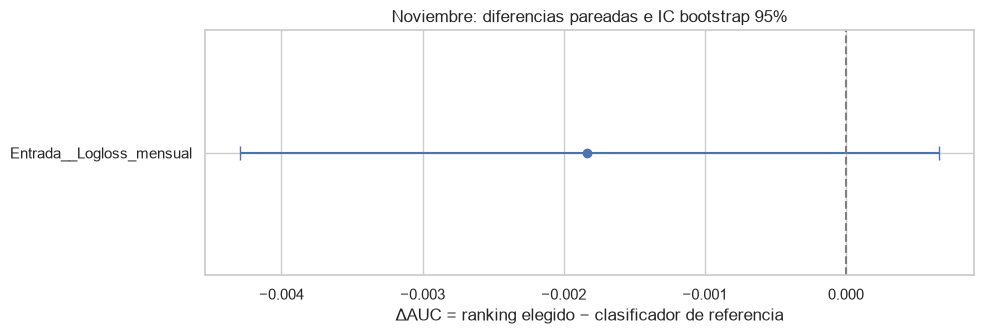

In [6]:
contrasts = pd.read_csv(OUT / "contrastes.csv")
display(contrasts)
fig, ax = plt.subplots(figsize=(10, 3.5))
auc_rows = contrasts.loc[contrasts.metrica.eq("AUC")].reset_index(drop=True)
ax.errorbar(auc_rows.diferencia, np.arange(len(auc_rows)),
            xerr=np.vstack([auc_rows.diferencia-auc_rows.IC95_inferior,
                            auc_rows.IC95_superior-auc_rows.diferencia]), fmt="o", capsize=5)
ax.axvline(0, linestyle="--", color="gray")
ax.set(yticks=np.arange(len(auc_rows)), yticklabels=auc_rows.referencia,
       xlabel="ΔAUC = ranking elegido − clasificador de referencia",
       title="Noviembre: diferencias pareadas e IC bootstrap 95%")
plt.tight_layout()
plt.show()

## Clientes nuevos, recurrentes y duraciones fuera de soporte

Que un cliente aparezca antes en train no es fuga para esta tarea si solo se utiliza
su pasado. Las features de entrada nunca toman su última fila. Los clientes de enero
llegan a una duración no vista en el mes de evaluación: se muestran por separado.
No se aplica un respaldo común: se compara directamente el extrapolado de cada árbol.

In [7]:
segments = pd.read_csv(OUT / "segmentos.csv")
chosen = list(dict.fromkeys([selection["ranking"], selection["clasificacion"], selection["control_matched"]]))
display(segments.loc[segments.mes.eq(11) & segments.config.isin(chosen),
                     ["config", "segmento", "n", "eventos", "AUC", "recall5", "lift5", "recall10", "lift10"]])
# Los scores de ranking tienen escala arbitraria. Se comparan sus ordenamientos.
nov_scores = p.loc[p.mes.eq(11)].pivot(index="id_cliente", columns="config", values="score")
display(nov_scores[chosen].corr(method="spearman"))

,config,segmento,n,eventos,AUC,recall5,lift5,recall10,lift10
96,Entrada__Logloss_mensual,nuevos,728,143,0.588560,0.097902,1.926290,0.174825,1.743462
97,Entrada__Logloss_mensual,recurrentes,8772,1296,0.619173,0.105710,2.112271,0.195988,1.958091
98,Entrada__Logloss_mensual,soporte,7241,1143,0.614952,0.107174,2.137872,0.193351,1.931108
99,Entrada__Logloss_mensual,fuera_soporte,2259,296,0.622239,0.091216,1.823517,0.135135,1.350753
108,Entrada__PairLogit_20k,nuevos,728,143,0.592409,0.090909,1.788698,0.167832,1.673724
109,Entrada__PairLogit_20k,recurrentes,8772,1296,0.616144,0.106481,2.127689,0.194444,1.942673
110,Entrada__PairLogit_20k,soporte,7241,1143,0.613536,0.107612,2.146598,0.189851,1.896156
111,Entrada__PairLogit_20k,fuera_soporte,2259,296,0.618463,0.091216,1.823517,0.148649,1.485829


config,Entrada__PairLogit_20k,Entrada__Logloss_mensual
config,,
Entrada__PairLogit_20k,1.000000,0.989266
Entrada__Logloss_mensual,0.989266,1.000000


## Conclusiones

Informe interpretativo de esta ejecución. No se convierten los scores de ranking
en probabilidades mediante una sigmoid sin calibración temporal.

In [8]:
display(Markdown((HERE / "REPORTE_RESULTADOS.md").read_text(encoding="utf-8")))

# Ranking mensual: resultados

## Conclusión

**Ranking no produjo una mejora concluyente sobre clasificación.** La variante elegida
con agosto–octubre ganó por solo 0,00056 de AUC media; en noviembre quedó por debajo:
**0,61621 frente a 0,61805**. ΔAUC = **−0,00183**, IC bootstrap pareado 95%
**[−0,00429; +0,00066]**. El intervalo incluye cero: no demuestra una caída concluyente,
pero tampoco respalda una mejora. No recomendaría sustituir el clasificador con esta evidencia.

Se completaron **64 ajustes**: dos bloques de features, cuatro variantes, dos semillas y
cuatro cortes temporales. Las métricas y pares se auditaron; el notebook está ejecutado.
No se leyó `test.csv`, no se modificó la entrega y no se añadieron dependencias.

## 1. Diseño de la comparación

El grupo de ranking es **el mes calendario**, no el cliente. Se construyen pares entre
un conversor y un no conversor de ese mismo mes. Que el segundo convierta posteriormente
no invalida su etiqueta negativa del mes actual. No se utilizan desenlaces futuros para
elegir pares. Todos los meses tienen igual número y peso total de pares.

Se probaron dos bloques de variables:

- **Entrada:** los 22 predictores de la primera fila conocida, más duración observada: 23.
- **Historia:** los 33 predictores de historia disponibles al mes evaluado, del constructor
  auditado de la sesión anterior. No incluyen ID ni duración final de la trayectoria.

Para cada bloque:

| Variante | Objetivo | Ponderación |
|---|---|---|
| Logloss natural | Clasificación binaria | Igual peso por fila |
| Logloss mensual | Clasificación binaria | Igual peso total por mes |
| PairLogit 20k | Ordenar positivo por encima de negativo | 20.000 pares/mes |
| PairLogit 100k | Igual objetivo de ranking | 100.000 pares/mes |

Se muestrearon pares uniformemente **sin reemplazo**, con los 20k anidados en los 100k.
No se enumeraron todos los millones de pares posibles. Los pesos de objetos no ponderan
PairLogit; el balance mensual se implementó en los propios pares de peso uno, conforme a
la [documentación de CatBoost](https://catboost.ai/docs/en/concepts/loss-functions-ranking).

Los modelos comparten 250 árboles, profundidad 4, learning rate 0,04, L2=12, una iteración
Newton por hoja, boosting Plain, sin bootstrap, random_strength=1 y los mismos parámetros
de discretización y one-hot. **Se comprobaron los parámetros efectivos**, no solo los
argumentos del constructor. Igual capacidad nominal no implica idéntica regularización
efectiva entre pérdidas o cantidades de pares. No se ajustaron hiperparámetros ni iteraciones
mirando validación. Por ello, estos números no se comparan como mejoras directas contra
sesiones anteriores con otros defaults/capacidades.

Semillas 42 y 137. Ensemble prefijado: promedio de los rangos percentiles de ambas semillas
dentro del mes, igual para clasificación y ranking. No necesita etiquetas; sus resultados
son **scores de ordenamiento, no probabilidades**. No se calculó Brier/log loss para ellos
ni se presentó una sigmoid sin calibrar como probabilidad.

## 2. Selección temporal y resultado mensual

Entrenamiento hasta el mes anterior; evaluación en agosto, septiembre, octubre y noviembre.
Los sobrevivientes pueden aparecer en train con su historia anterior, como en operación.
Las features se verificaron invariantes al retirar el futuro y al modificar las etiquetas.

Se eligieron por separado el mejor ranking y el mejor clasificador según **AUC media
agosto–octubre**, antes de ajustar noviembre. Ambos seleccionados usan Entrada; por tanto,
el mejor clasificador coincide con el control de Logloss mensual de las mismas features.

| Features | Variante | AUC media ago–oct | AUC noviembre |
|---|---|---:|---:|
| Entrada | **PairLogit 20k — ranking seleccionado** | **0,63067** | 0,61621 |
| Entrada | **Logloss mensual — clasificador seleccionado** | 0,63011 | 0,61805 |
| Entrada | Logloss natural | 0,63000 | 0,61858 |
| Historia | Logloss natural | 0,62982 | 0,61748 |
| Historia | Logloss mensual | 0,62977 | 0,61729 |
| Historia | PairLogit 20k | 0,62946 | 0,61418 |
| Entrada | PairLogit 100k | 0,62748 | 0,61335 |
| Historia | PairLogit 100k | 0,62620 | 0,61068 |

La mejor cifra de noviembre corresponde a Logloss natural con Entrada, pero **no se
reeligió el candidato usando noviembre**. Este mes ya había sido inspeccionado en sesiones
anteriores: es una comprobación retrospectiva, no un holdout externo independiente.

El ranking seleccionado y su clasificador comparable, por ventana:

| Mes | Ranking | Clasificación |
|---|---:|---:|
| Agosto | 0,63132 | 0,63020 |
| Septiembre | 0,62781 | 0,62730 |
| Octubre | 0,63289 | 0,63284 |
| Noviembre | 0,61621 | 0,61805 |

Los tres incrementos iniciales son pequeños y desaparecen en noviembre. En noviembre el
ranking también pierde en ambas semillas por separado: 0,61640 vs 0,61733 con semilla 42,
y 0,61584 vs 0,61864 con semilla 137. No depende únicamente de cómo se promediaron los rangos.

## 3. ¿Mejora la priorización de clientes?

Noviembre tiene **9.500 clientes y 1.439 conversiones** (tasa 15,15%). Para los dos candidatos
seleccionados, el top 5% contiene 475 clientes y el top 10%, 950:

| Métrica de noviembre | Ranking 20k | Clasificador mensual |
|---|---:|---:|
| AUC | 0,61621 | 0,61805 |
| Gini | 0,23243 | 0,23609 |
| Conversores capturados en top 5% | **150** | 149 |
| Precision top 5% | 31,58% | 31,37% |
| Recall top 5% | 10,42% | 10,35% |
| Lift top 5% | 2,085 | 2,071 |
| Conversores capturados en top 10% | 273 | **278** |
| Precision top 10% | 28,74% | 29,26% |
| Recall top 10% | 18,97% | 19,32% |
| Lift top 10% | 1,897 | 1,932 |

El ranking captura **uno más en el top 5%, pero cinco menos en el top 10%**. En el top 10%
también capturó menos conversores en agosto, septiembre y octubre: **5, 6 y 4 menos**,
respectivamente, aun cuando la AUC global fuera ligeramente mayor. Mejorar el orden global
no garantiza mejorar las primeras posiciones. No hay una ventaja operacional consistente.
Intervalos bootstrap del cambio en recall, en puntos
porcentuales: top 5% **+0,069 [−0,493; +0,679]**; top 10% **−0,347 [−0,931; +0,213]**.
Ambos incluyen cero. Los top-K son análisis secundarios, no una reselección de ganador.

En los empates del umbral se usa captura esperada bajo desempate uniforme. Por eso algunas
otras variantes tienen capturas fraccionarias, como 155,5; no representan medio cliente
real ni se desempata a favor de los positivos. La fórmula fue verificada independientemente.

**Interpretación comercial:** un lift de aproximadamente 2 significa mayor concentración
de conversiones observadas que una selección aleatoria. No demuestra que contactar a esos
clientes cause conversiones adicionales: estos datos no estiman uplift ni efecto de campaña.

## 4. Insights adicionales

### Los rankings aprendidos son muy parecidos

La correlación de Spearman entre los dos candidatos en noviembre es **0,9893**. Cambiar
la pérdida alteró algunos lugares, pero no descubrió un ordenamiento radicalmente diferente.
Esto encaja con que el clasificador ya captura buena parte de la señal de orden disponible;
no demuestra que sea un óptimo ni un techo definitivo de AUC.

### Más pares no ayudaron

100k pares obtuvieron menor AUC que 20k en las cuatro ventanas y en ambos bloques de
features. Los 20k cubrieron todos los positivos y, en el peor mes/semilla, el **89,13%**
de los negativos; los 100k cubrieron todos los positivos y aproximadamente el **99,99%** de
los negativos (99,9886% antes de redondear).

La mayor cobertura no se tradujo en mejor validación. No se puede atribuir exclusivamente
a sobreajuste o regularización por ruido: no se aisló el mecanismo y la regularización
óptima puede cambiar con el objetivo y el número de pares. Los pares reutilizan clientes;
100.000 pares no equivalen a 100.000 observaciones independientes nuevas.

El coste medio por ajuste fue aproximadamente **7 segundos con 20k**, **14 segundos con
100k**, frente a **2–3 segundos** de clasificación. Son tiempos de esta ejecución, no un
benchmark de hardware. Se incrementó el coste sin evidencia de una mejora de desempeño.

### La historia adicional no mejoró consistentemente

La foto de entrada + duración seleccionó mejores candidatos de ranking y clasificación
en agosto–octubre. La historia no aporta una mejora consistente en este diseño; esto es
compatible con el EDA de variables casi congeladas y una interacción temporal peculiar.
No prueba que toda historia sea inútil ni que las variables estáticas estén libres de fuga.

### Nuevos vs recurrentes y extrapolación temporal

| Segmento de noviembre | Clientes | AUC ranking | AUC clasificación |
|---|---:|---:|---:|
| Nuevos | 728 | 0,59241 | 0,58856 |
| Recurrentes | 8.772 | 0,61614 | 0,61917 |
| Duraciones presentes en train | 7.241 | 0,61354 | 0,61495 |
| Duración 11, no presente en train hasta octubre | 2.259 | 0,61846 | 0,62224 |

El ranking tiene mejor AUC puntual en nuevos, pero no en recurrentes. Son análisis de
subgrupos sin IC propio ni selección por segmento: no justifican construir retrospectivamente
una regla híbrida. Además, entre nuevos tampoco mejora aquí el recall del top 5%/10%.

Los 2.259 clientes de enero requieren aplicar los árboles fuera del rango de duración
entrenado. Se compararon las predicciones directas de cada modelo, **sin respaldo común**,
y se reportaron aparte. Esto no debe confundirse con validar una relación aprendida para Z=11.

## 5. Límites y decisión

- Mantener clasificación como referencia. La formulación de ranking es coherente con
  AUC/Gini, pero **esta configuración no aporta una mejora concluyente ni una ganancia
  consistente en top-K**.
- Los IC usan 2.000 remuestreos pareados de clientes de noviembre. Condicionan a los modelos
  ajustados; no incorporan toda la variabilidad de reentrenar ni las exploraciones previas.
- El entrenamiento contiene pocos meses, aunque tenga miles de clientes y muchos pares.
  No se equipara el número de pares a evidencia temporal independiente. Dos semillas son
  un control limitado de sensibilidad, no una garantía de estabilidad.
- No se ensayó NDCG@K: optimizar exclusivamente las primeras posiciones es otra pregunta.
  Esta prueba se centró en ranking pairwise orientado al orden global evaluado por AUC.
- Los scores no están calibrados. Antes de usarlos como probabilidades habría que calibrar
  con predicciones temporales fuera de entrenamiento; no se hizo para fabricar una mejora.
- La disponibilidad histórica de las covariables sigue siendo una hipótesis. Las pruebas
  de código previenen fuga introducida por las transformaciones, no certifican que la fuente
  original no propagara hacia atrás una foto posterior del cliente.

## Entregables y reproducción

`Ranking_mensual.ipynb` contiene las métricas, gráficos, sensibilidad por semillas,
contrastes y este reporte. `PROTOCOLO.md` se fijó antes de entrenar. `resultados/` guarda
los parámetros efectivos, hashes, cobertura y hashes de pares, selección previa a noviembre,
637.600 predicciones individuales sumando ambas semillas y 318.800 scores de ensemble
(incluyen distintas configuraciones).

La auditoría independiente reprodujo AUC y top-K, el promedio de rangos y la equivalencia
del bootstrap ponderado con remuestrear clientes. También comprobó etiquetas contra train,
que los pares pasados no cambian al añadir meses, y que los hiperparámetros compartidos
coinciden realmente entre objetivos. No se modificaron notebooks o entregas anteriores.

Desde la raíz, con el entorno existente de Python 3.13:

```powershell
.venv\Scripts\python.exe nuevas-tareas\ranking_mensual\experimento.py
.venv\Scripts\python.exe nuevas-tareas\ranking_mensual\verificar.py
.venv\Scripts\python.exe nuevas-tareas\ranking_mensual\ejecutar_notebook.py
```
